<a href="https://colab.research.google.com/github/aubricot/Mouse_Model_GMM/blob/main/mouse_gmm_demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 3D Geometric Morphometrics in R — mouse crania

**Digital Imaging Workshop · Florida Museum of Natural History · 27 October 2026**

A beginner's walkthrough of a full 3D GMM analysis: landmarks in, shape results out.
Everything runs in the browser, so there is nothing to install on your own machine.

**Before you start:** go to *Runtime → Change runtime type* and make sure the
language is set to **R**, not Python.

The data is the SlicerMorph mouse cranium set: 62 inbred strains, 51 landmarks each.

Adapted from `lm_analysis.R` (Wolcott et al. 2025) for teaching.

## 1. Install and load packages

`geomorph` is the workhorse package for geometric morphometrics in R. On Linux
(including Colab) we pull pre-built binaries from Posit's package manager, which
takes seconds instead of the several minutes a source build needs.

`rgl` draws interactive 3D windows, which do not exist on a cloud machine, so we
switch it to a "null device" before loading anything. Skip that and geomorph's
3D plots will error out.

In [14]:
# PPM serves pre-built binaries; HTTPUserAgent is what unlocks them.
options(
  repos = c(CRAN = paste0("https://packagemanager.posit.co/cran/__linux__/",
                          system("lsb_release -cs", intern = TRUE), "/latest")),
  HTTPUserAgent = sprintf("R/%s R (%s)", getRversion(), paste(getRversion(),
                          R.version$platform, R.version$arch, R.version$os)),
  rgl.useNULL = TRUE)   # no screen in Colab; must be set before rgl loads

pkgs <- c("jsonlite", "geomorph", "ggplot2", "ggforce", "concaveman", "glue")
install.packages(pkgs)
invisible(lapply(pkgs, library, character.only = TRUE))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



## 2. Download the landmark data

We only need the `LMs/` folder, so we use a *sparse checkout*: git fetches the
file list but downloads only that one directory. The full repository is ~113 MB
of 3D models we do not need for this analysis.

In [15]:
#@markdown ### Where to save results
save_to  = "Colab runtime (deleted when the session ends)" #@param ["Colab runtime (deleted when the session ends)", "My Google Drive"]
repo_url = "https://github.com/aubricot/Mouse_Models.git" #@param {type:"string"}
project  = "GMM" #@param {type:"string"}

base_wd <- if (grepl("Drive", save_to)) "/content/drive/MyDrive" else "/content"
if (!dir.exists(base_wd)) stop(base_wd, " not found - is Google Drive mounted?")
setwd(base_wd)

repo_dir <- sub("\\.git$", "", basename(repo_url))
if (!dir.exists(repo_dir))
  system(paste("git clone --depth 1 --filter=blob:none --sparse", repo_url))
system(sprintf("cd %s && git sparse-checkout set LMs", repo_dir))

setwd(repo_dir)
lm_files  <- sort(list.files("LMs", pattern = "\\.mrk\\.json$", full.names = TRUE))
meta_file <- "demo_metadata.csv"

cat("\033[92mWorking directory:\n", getwd(), "\033[0m\n")
cat("Found", length(lm_files), "landmark files\n")

Working directory:
 /content/Mouse_Models 
Found 62 landmark files


## 3. Read the landmarks into a 3D array

A `.mrk.json` file is 3D Slicer's markups format. Each one holds a list of
control points with an `[X, Y, Z]` position.

geomorph wants all specimens stacked in a single **3D array** with the shape
`p x k x n`: `p` landmarks, `k` coordinates (3), `n` specimens. Picture a deck of
cards, one card per specimen, each card a table of 51 rows by 3 columns.

In [16]:
read_landmarks <- function(path) {
  pos <- jsonlite::fromJSON(path)$markups$controlPoints[[1]]$position
  if (is.list(pos)) do.call(rbind, pos) else pos}

specimen_ids <- sub("\\.mrk\\.json$", "", basename(lm_files))
lm_list      <- lapply(lm_files, read_landmarks)

# Stack into the p x k x n array geomorph expects.
A <- array(unlist(lm_list),
           dim      = c(nrow(lm_list[[1]]), 3, length(lm_list)),
           dimnames = list(NULL, c("X", "Y", "Z"), specimen_ids))

cat(sprintf("Array: %d landmarks x 3 coords x %d specimens\n", dim(A)[1], dim(A)[3]))
A[, , 1]   # all landmarks for the first specimen

Array: 51 landmarks x 3 coords x 62 specimens


X,Y,Z
-9.05953,-25.24580,10.15460
-9.32151,-25.24210,10.16420
-7.28620,-18.93070,11.37060
-8.87191,-17.52410,11.96270
-9.30674,-18.08750,11.80070
-9.98344,-17.33100,11.94680
-11.20960,-18.97670,11.38040
-4.22636,-16.73500,7.99301
-14.27200,-16.74220,7.87027
-3.52164,-12.77180,6.67517


## 4. Build the specimen metadata table

Shape data alone cannot tell you *which* groups differ — you need a table saying
what each specimen is. One row per specimen, matched by ID.

**The locality and diet columns below are invented for teaching.** They are
random, so they should show no relationship with shape; that makes them a useful
control. `strain_group` is derived from the strain names and does carry real
structure.

In [17]:
info <- read.csv(meta_file)

# Row order MUST match the array's specimen order, or groups get mislabelled.
info <- info[match(dimnames(A)[[3]], info$specimen_id), ]

locality <- factor(info$collection_locality)
diet     <- factor(info$diet)

str(info)

'data.frame':	62 obs. of  6 variables:
 $ specimen_id        : chr  "129S1_SVIMJ" "129X1_SVJ" "A_J" "AKR_J" ...
 $ genus              : chr  "Mus" "Mus" "Mus" "Mus" ...
 $ species            : chr  "musculus" "musculus" "musculus" "musculus" ...
 $ collection_locality: chr  "Jackson_Laboratory" "Taconic_Biosciences" "Jackson_Laboratory" "Charles_River" ...
 $ diet               : chr  "peanut_butter" "yogurt" "rolled_oats" "yogurt" ...
 $ strain             : chr  "LB-SV-01" "LB-SV-02" "LB-IN-02" "LB-IN-01" ...


## 5. Generalized Procrustes Analysis (GPA)

Raw landmarks carry differences in **position, orientation, and size** that have
nothing to do with shape — a skull scanned at a different angle is not a
different shape. GPA translates, rotates, and scales every specimen onto a common
reference so that only shape variation is left.

Two useful things come out of it: `$coords`, the aligned shapes, and `$Csize`,
centroid size — a measure of overall size, kept aside so you can test allometry
later.

These landmarks are all *fixed* points. If your own data has curves or surfaces,
pass `curves =` / `surfaces =` so semi-landmarks slide.


Call:
gpagen(A = A, print.progress = FALSE) 



Generalized Procrustes Analysis
with Partial Procrustes Superimposition

51 fixed landmarks
0 semilandmarks (sliders)
3-dimensional landmarks
2 GPA iterations to converge


Consensus (mean) Configuration

              X             Y             Z
1  -0.212131943 -3.278451e-03  0.0245862267
2  -0.212106323  2.516216e-03  0.0247784297
3  -0.077115565 -4.369208e-02  0.0626555301
4  -0.046875155 -9.913693e-03  0.0776962859
5  -0.059686492 -9.781591e-05  0.0737193080
6  -0.046616178  1.122839e-02  0.0772075399
7  -0.078434991  4.332300e-02  0.0624291405
8  -0.019952022 -1.193271e-01 -0.0093701136
9  -0.017730521  1.203150e-01 -0.0105364365
10  0.065437846 -1.323652e-01 -0.0288827712
11  0.045719705 -6.443843e-02  0.0741092590
12  0.041304550  6.291967e-02  0.0744976364
13  0.066957687  1.331943e-01 -0.0277249672
14  0.107414925 -1.790979e-03  0.0863286391
15  0.200633183 -1.229793e-03  0.0694250450
16  0.271636136 -1.574921e-03  0.037496987

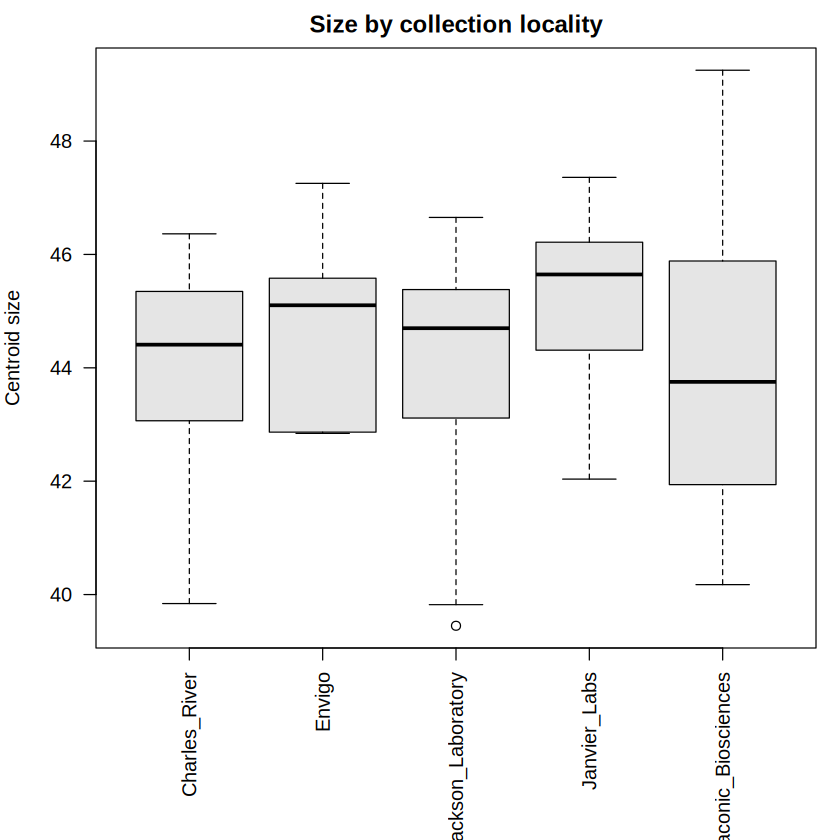

In [18]:
Y.gpa <- gpagen(A, print.progress = FALSE)
summary(Y.gpa)

# Centroid size by group: is one group simply bigger?
par(mar = c(8, 4, 2, 1))
boxplot(Y.gpa$Csize ~ locality, las = 2, xlab = "", ylab = "Centroid size",
        main = "Size by collection locality", col = "grey90")

## 6. Check the alignment before trusting it

Always look before analysing. A single mislandmarked specimen can dominate a PCA
and send you chasing a result that is really a typo.

`plotOutliers` ranks specimens by how far they sit from the mean shape. A big gap
at the top of that plot is worth investigating in Slicer before going further.

[1] "SF"      "PERC"    "SPRET"   "C3H_HEJ" "C3HeB"   "WSB"

Specimen closest to the mean: FVB_NJ 


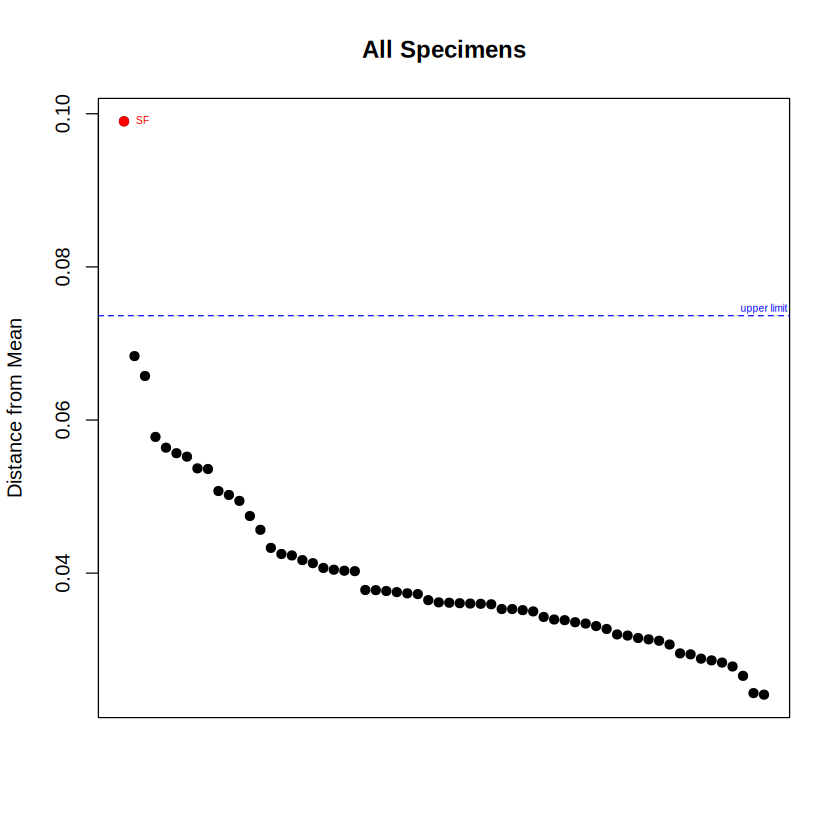

In [19]:
outliers <- plotOutliers(Y.gpa$coords)
head(outliers)

# Which specimen is closest to the mean shape?
# Useful as a reference model.
mean_spec <- findMeanSpec(Y.gpa$coords)
cat("Specimen closest to the mean:", dimnames(A)[[3]][mean_spec], "\n")

## 7. Principal Component Analysis (PCA)

After GPA each specimen is 153 numbers (51 landmarks x 3 coordinates), far too
many dimensions to look at. PCA condenses those correlated coordinates into a few
independent **shape axes**. Plotting the first two gives you *morphospace*.

Check the percentages: if PC1 and PC2 together explain a large share of the
variation, a 2D plot is a fair summary. If they explain little, specimens that
overlap on screen may still differ along higher axes.

PC1: 21.9%   PC2: 10.1%   PC1+PC2: 32.0%


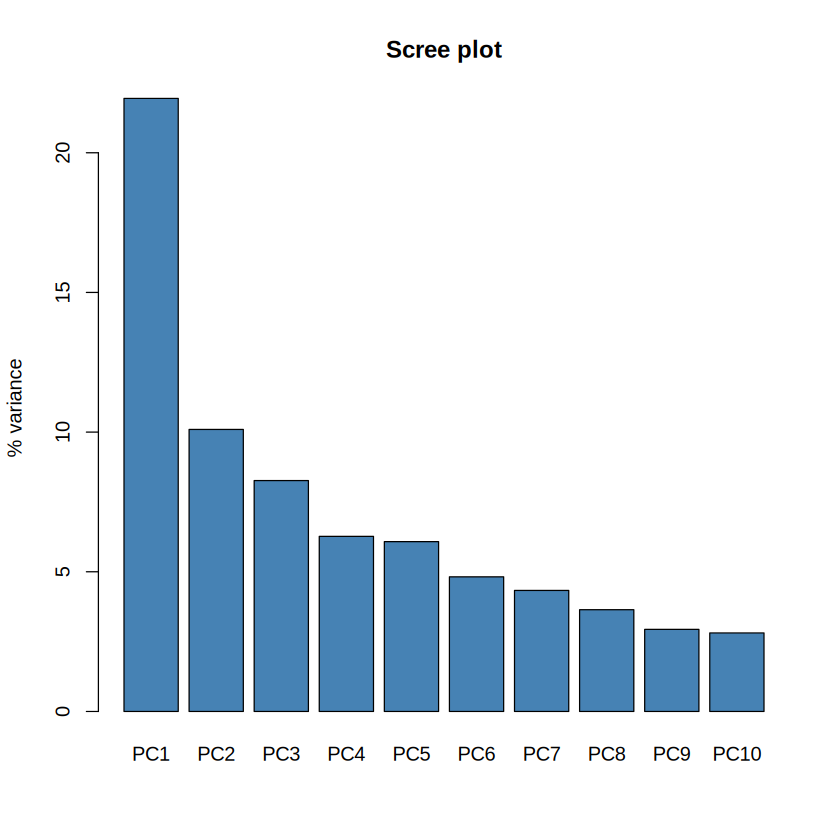

In [20]:
pca <- gm.prcomp(Y.gpa$coords)

pct <- 100 * pca$d / sum(pca$d)        # percent variance per axis
cat(sprintf("PC1: %.1f%%   PC2: %.1f%%   PC1+PC2: %.1f%%\n",
            pct[1], pct[2], pct[1] + pct[2]))

barplot(pct[1:10], names.arg = paste0("PC", 1:10),
        ylab = "% variance", main = "Scree plot", col = "steelblue")

## 8. Plot morphospace, coloured by group

Points close together are similar in shape; points far apart differ more.
Separation **along an axis** means those specimens differ in the shape change
that axis describes.

Compare the two plots. `strain_group` should show structure — wild-derived
strains pulling away from classic inbred lines. `diet` is random noise, so it
should show none. That contrast is the point: colour alone always *looks* like
something, and a control factor is how you tell real grouping from pattern you
have talked yourself into.

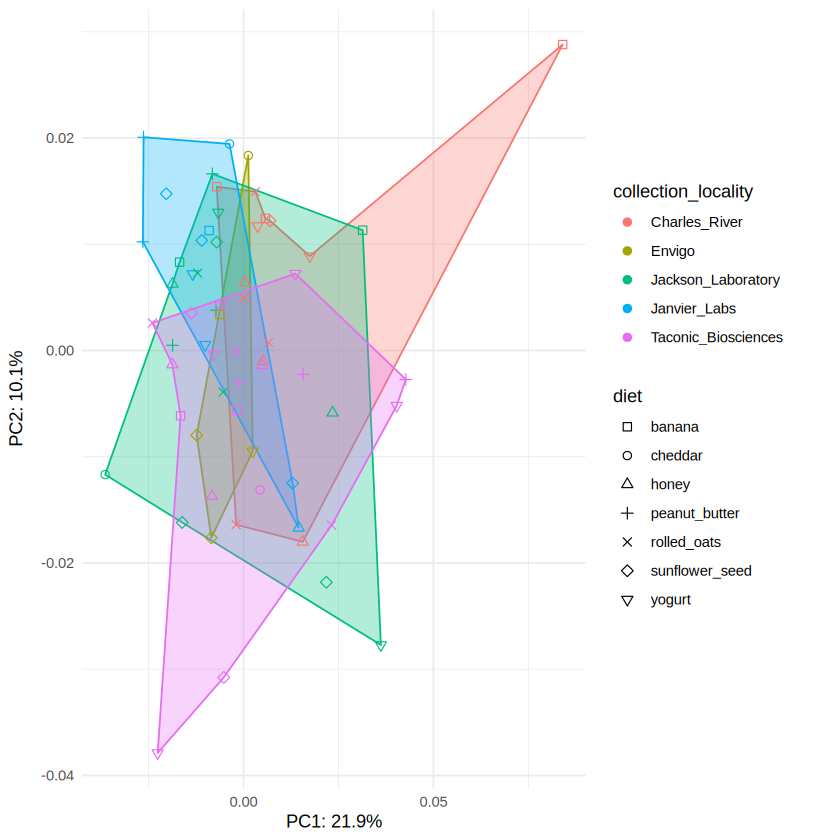

In [21]:
library(ggplot2); library(ggforce); library(glue)

#@markdown ### PCA plot settings
pc_x       = 1 #@param {type:"integer"}
pc_y       = 2 #@param {type:"integer"}
color_by   = "collection_locality" #@param ["collection_locality", "diet"]
shape_by   = "diet" #@param ["none", "collection_locality", "diet"]
draw_hulls = TRUE #@param {type:"boolean"}
label_hulls = FALSE #@param {type:"boolean"}

pct = 100 * pca$d / sum(pca$d)

dtp = data.frame(PCx = pca$x[, pc_x],
                 PCy = pca$x[, pc_y],
                 grp = factor(info[[color_by]]))
if (shape_by != "none") dtp$shp = factor(info[[shape_by]])

p = ggplot(dtp, aes(x = PCx, y = PCy, col = grp)) + theme_minimal() +
  labs(x = glue("PC{pc_x}: {round(pct[pc_x], 1)}%"),
       y = glue("PC{pc_y}: {round(pct[pc_y], 1)}%"),
       col = color_by, shape = shape_by)

if (draw_hulls) {
  hull_aes = if (label_hulls) aes(fill = grp, label = grp) else aes(fill = grp)
  p = p + geom_mark_hull(hull_aes, concavity = 5, expand = 0, radius = 0,
                         label.buffer = unit(1, "mm"), con.cap = 0,
                         show.legend = FALSE)
}

p = p + if (shape_by == "none") geom_point(size = 2) else geom_point(aes(shape = shp), size = 2)
if (shape_by != "none") p = p + scale_shape_manual(values = seq(0, 8))

p

## 9. What shape change does each axis describe?

A PC is only interpretable once you can see it. Here we compare the shapes at
each end of an axis against the mean shape.

geomorph's `plotRefToTarget` normally opens an interactive 3D window, which does
not exist on a cloud machine — so we draw flat projections instead. Grey points
are the mean shape, red points the target, and each arrow shows how one landmark
moves.

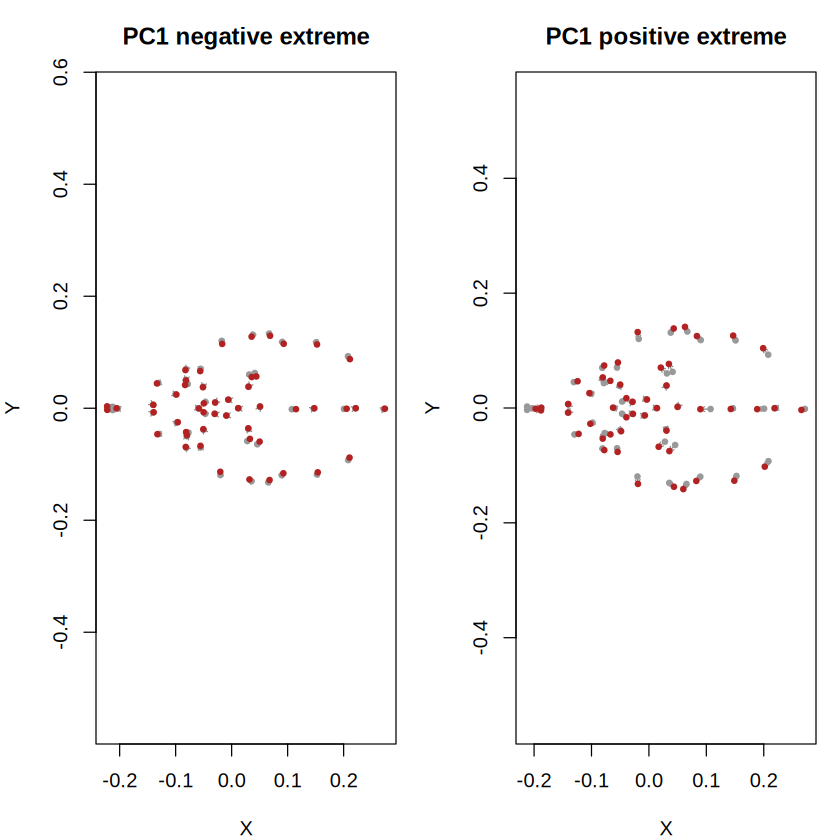

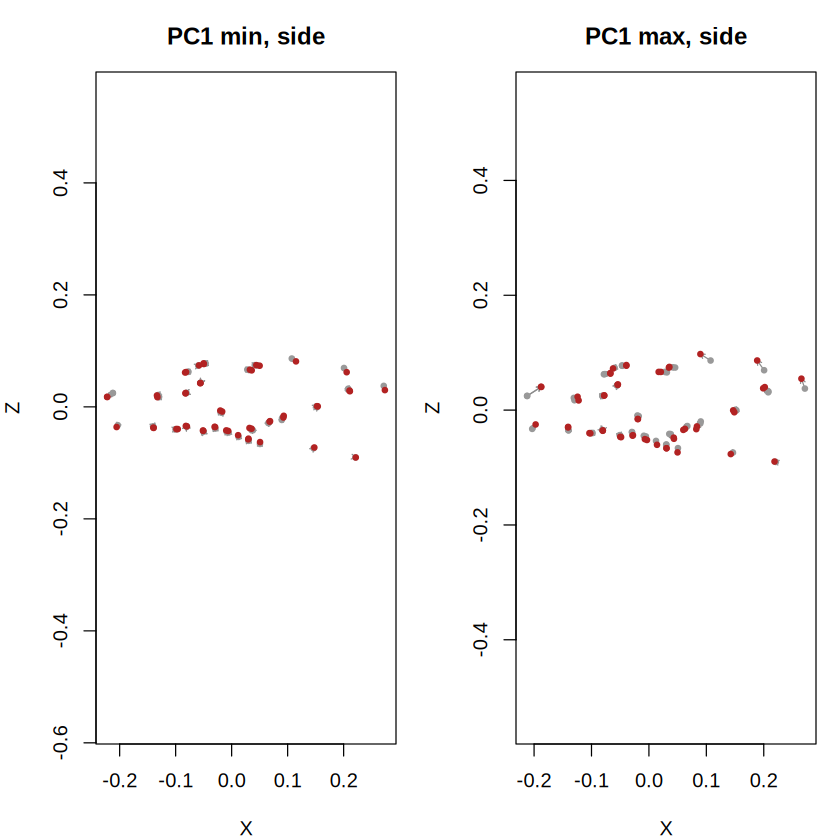

In [30]:
ref <- mshape(Y.gpa$coords)

plot_shape_change <- function(ref, target, main, axes = c(1, 2)) {
  labs <- c("X", "Y", "Z")[axes]
  plot(rbind(ref[, axes], target[, axes]), type = "n", asp = 1,
       xlab = labs[1], ylab = labs[2], main = main)
  arrows(ref[, axes[1]], ref[, axes[2]], target[, axes[1]], target[, axes[2]],
         length = 0.04, col = "grey55")
  points(ref[, axes],    pch = 19, cex = 0.6, col = "grey60")
  points(target[, axes], pch = 19, cex = 0.6, col = "firebrick")
}

par(mfrow = c(1, 2), mar = c(4, 4, 3, 1))
plot_shape_change(ref, pca$shapes$shapes.comp1$min, "PC1 negative extreme")
plot_shape_change(ref, pca$shapes$shapes.comp1$max, "PC1 positive extreme")
par(mfrow = c(1, 1))

# Side view (X-Z) of the same comparison:
par(mfrow = c(1, 2), mar = c(4, 4, 3, 1))
plot_shape_change(ref, pca$shapes$shapes.comp1$min, "PC1 min, side", axes = c(1, 3))
plot_shape_change(ref, pca$shapes$shapes.comp1$max, "PC1 max, side", axes = c(1, 3))
par(mfrow = c(1, 1))

## Compare a specimen to the mean shape

`plotRefToTarget` shows how one specimen differs from the mean (the reference).
Three views of the same comparison:

- **TPS** – a thin-plate spline grid, warped to show where the shape stretches and compresses
- **Vector** – "lollipops" from each mean landmark to the specimen's landmark
- **Points** – both landmark sets overlaid

These are interactive 3D plots: drag to rotate, scroll to zoom. `mag = 3` exaggerates the differences so they are easier to see.

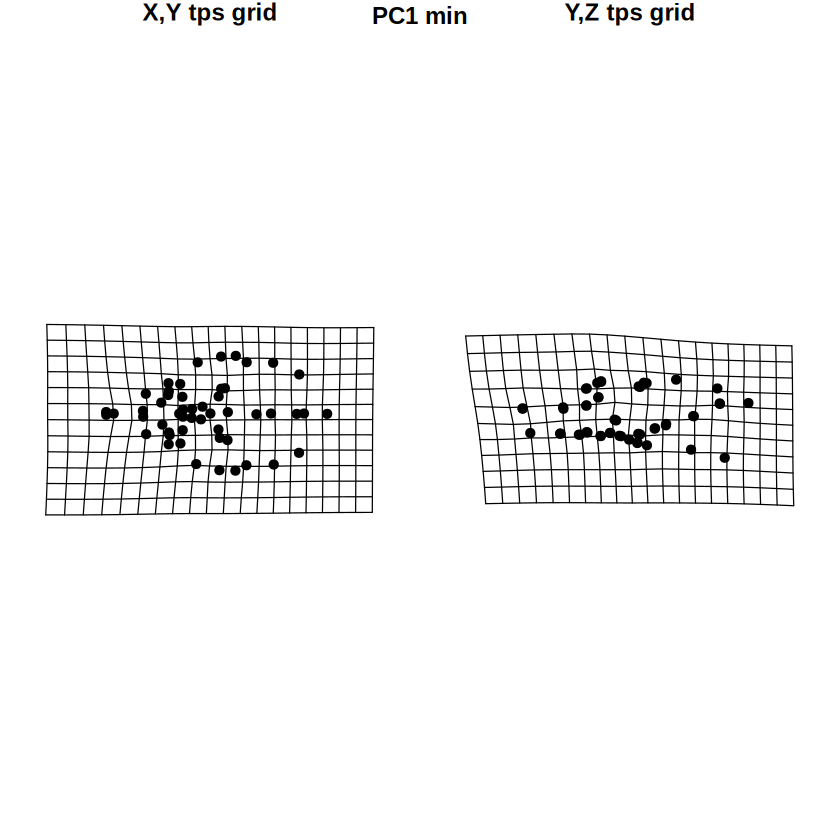

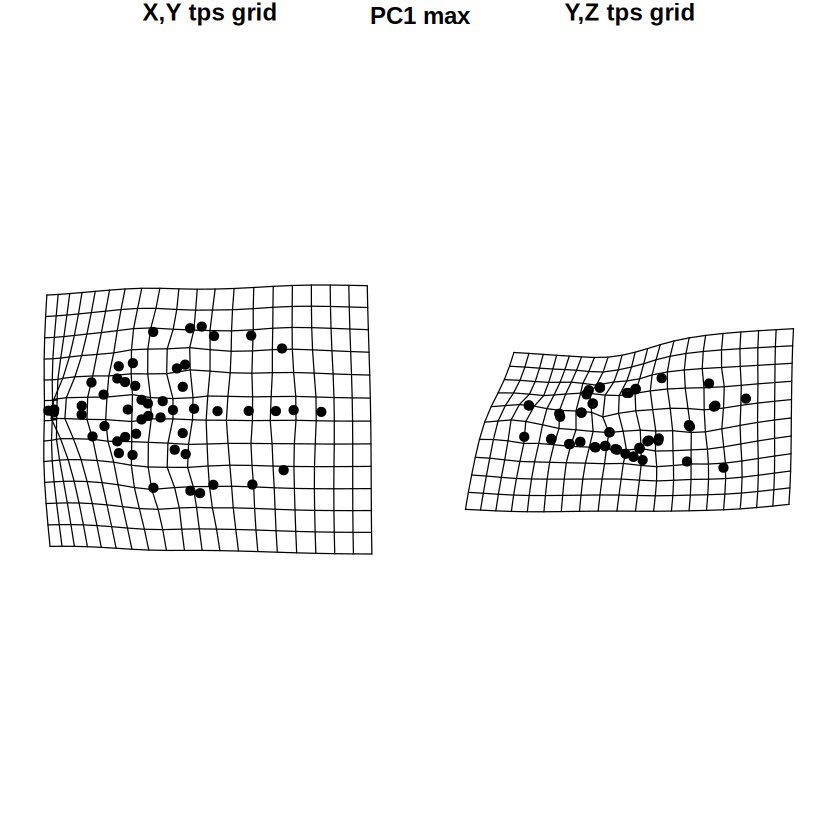

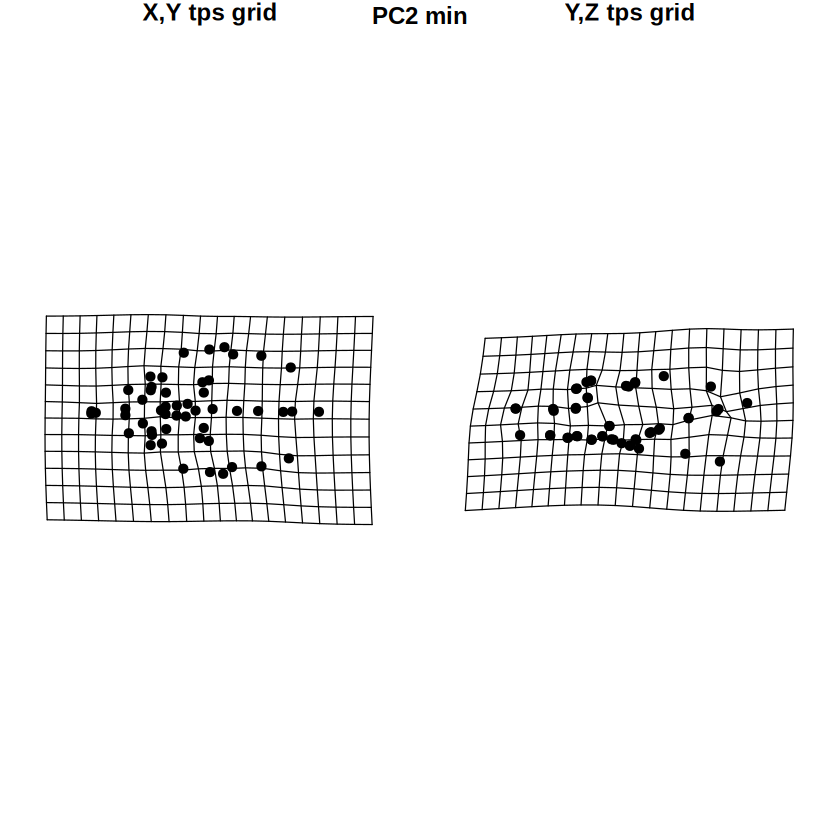

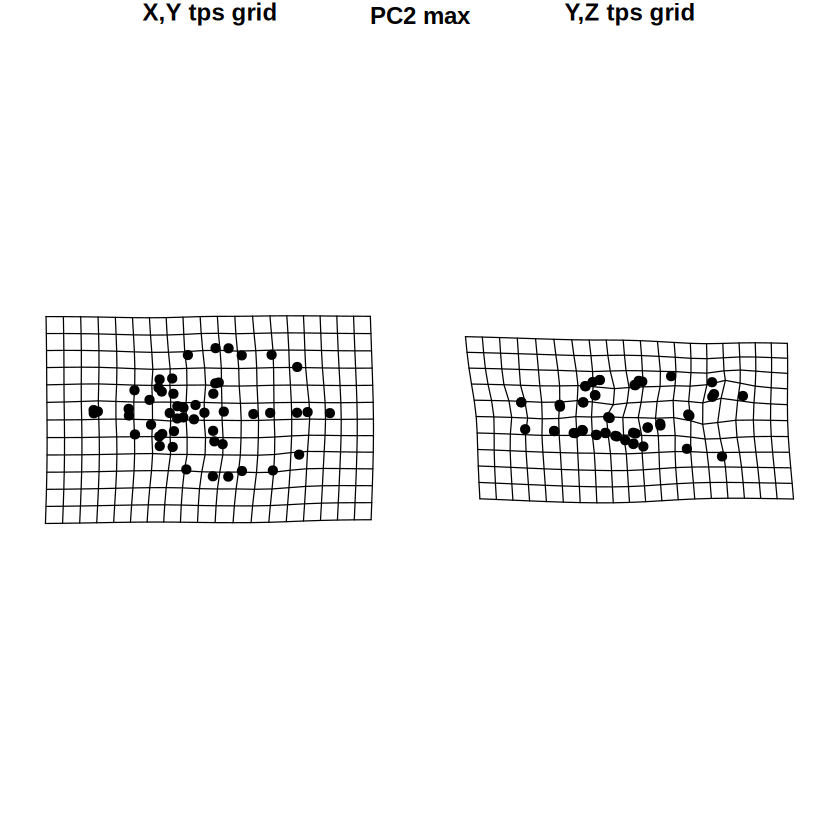

In [31]:
# Deformation grids: min and max of the plotted PCs against the mean
for (pc in unique(c(pc_x, pc_y))) {
  s <- pca$shapes[[paste0("shapes.comp", pc)]]
  plotRefToTarget(ref, s$min); title(sprintf("PC%d min", pc), line = -1, outer = TRUE)
  plotRefToTarget(ref, s$max); title(sprintf("PC%d max", pc), line = -1, outer = TRUE)}

## 10. Procrustes ANOVA: does group actually explain shape?

The PCA plot is descriptive. To ask whether a factor explains shape variation you
fit a model. `procD.lm` runs an ANOVA on shape using permutation rather than the
usual normal-theory assumptions, which do not hold for Procrustes coordinates.

Read the **Rsq** column (how much variation the term explains) alongside the
p-value. With 62 specimens, a term can be significant and still explain very
little.

Run the control too. `diet` is random, so a significant result there would mean
something is wrong with the pipeline.

In [ ]:
gdf <- geomorph.data.frame(Y.gpa, locality = locality, diet = diet)

# A) Null model: shape explained by size alone
fit.null <- procD.lm(coords ~ log(Csize), data = gdf, print.progress = FALSE)
anova(fit.null)

# B) Common slopes: groups differ in mean shape but share the size trend
fit.common <- procD.lm(coords ~ log(Csize) + locality, data = gdf,
                       SS.type = "III", print.progress = FALSE)
anova(fit.common)

# C) Unique slopes: groups also differ in how shape changes with size
fit.unique <- procD.lm(coords ~ log(Csize) * locality, data = gdf,
                       SS.type = "III", print.progress = FALSE)
anova(fit.unique)

# Which model fits best?
anova(fit.null, fit.common, fit.unique)

# Which pairs of groups actually differ?
PW <- pairwise(fit = fit.unique, fit.null = fit.common, groups = locality)
summary(PW, confidence = 0.95)


Analysis of Variance, using Residual Randomization
Permutation procedure: Randomization of null model residuals 
Number of permutations: 1000 
Estimation method: Ordinary Least Squares 
Sums of Squares and Cross-products: Type I 
Effect sizes (Z) based on F distributions

           Df       SS        MS     Rsq     F      Z Pr(>F)    
log(Csize)  1 0.008109 0.0081094 0.07526 4.883 4.3513  0.001 ***
Residuals  60 0.099645 0.0016608 0.92474                        
Total      61 0.107755                                          
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Call: procD.lm(f1 = coords ~ log(Csize), data 
= gdf, print.progress = FALSE)


Analysis of Variance, using Residual Randomization
Permutation procedure: Randomization of null model residuals 
Number of permutations: 1000 
Estimation method: Ordinary Least Squares 
Sums of Squares and Cross-products: Type III 
Effect sizes (Z) based on F distributions

           Df       SS        MS     Rsq      F      Z Pr(>F)    
log(Csize)  1 0.007214 0.0072140 0.06695 4.4102 4.1450  0.001 ***
locality    4 0.008044 0.0020109 0.07465 1.2294 1.2174  0.096 .  
Residuals  56 0.091602 0.0016357 0.85009                         
Total      61 0.107755                                           
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Call: procD.lm(f1 = coords ~ log(Csize) + 
locality, SS.type = "III", data = gdf, 
print.progress = FALSE)


Analysis of Variance, using Residual Randomization
Permutation procedure: Randomization of null model residuals 
Number of permutations: 1000 
Estimation method: Ordinary Least Squares 
Sums of Squares and Cross-products: Type III 
Effect sizes (Z) based on F distributions

                    Df       SS        MS     Rsq      F      Z Pr(>F)
log(Csize)           1 0.002366 0.0023660 0.02196 1.4761 1.0723  0.125
locality             4 0.008281 0.0020702 0.07685 1.2915 1.2734  0.101
log(Csize):locality  4 0.008251 0.0020626 0.07657 1.2868 1.2614  0.105
Residuals           52 0.083351 0.0016029 0.77353                     
Total               61 0.107755                                       

Call: procD.lm(f1 = coords ~ log(Csize) * 
locality, SS.type = "III", data = gdf, 
print.progress = FALSE)


Sums of Squares calculations for 2 models: 1000 permutations.
  |======================================================================| 100%



Analysis of Variance, using Residual Randomization
Permutation procedure: Randomization of null model residuals 
Number of permutations: 1000 
Estimation method: Ordinary Least Squares 
Effect sizes (Z) based on F distributions

                               ResDf Df      RSS        SS        MS      Rsq
coords ~ log(Csize) (Null)        60  1 0.099645                     0.000000
coords ~ log(Csize) + locality    56  4 0.091602 0.0080437 0.0020109 0.074648
coords ~ log(Csize) * locality    52  8 0.083351 0.0162942 0.0020368 0.151216
Total                             61    0.107755                             
                                    F      Z Pr(>F)  
coords ~ log(Csize) (Null)                           
coords ~ log(Csize) + locality 1.2294 1.2174  0.096 .
coords ~ log(Csize) * locality 1.2707 1.4830  0.066 .
Total                                                
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


Pairwise comparisons

Groups: Charles_River Envigo Jackson_Laboratory Janvier_Labs Taconic_Biosciences 

RRPP: 1000 permutations

LS means:
Vectors hidden (use show.vectors = TRUE to view)

Pairwise distances between means, plus statistics
                                                d  UCL (95%)          Z Pr > d
Charles_River:Envigo                   0.02537007 0.03915438 -1.2489411  0.899
Charles_River:Jackson_Laboratory       0.02057192 0.03288553 -0.9594470  0.819
Charles_River:Janvier_Labs             0.02434919 0.03603812 -0.5981809  0.700
Charles_River:Taconic_Biosciences      0.01921497 0.03024240 -1.3328393  0.902
Envigo:Jackson_Laboratory              0.02010014 0.03526052 -2.0516217  0.979
Envigo:Janvier_Labs                    0.03026563 0.04113817 -0.3519076  0.638
Envigo:Taconic_Biosciences             0.02110699 0.03378235 -2.1059263  0.977
Jackson_Laboratory:Janvier_Labs        0.02057156 0.02819733 -0.4757739  0.680
Jackson_Laboratory:Taconic_Biosciences 0.0153378

## 11. Allometry: shape change that comes with size

Bigger animals are not just scaled-up small ones; proportions shift too. These
plots show the size-related part of shape variation, coloured by group.

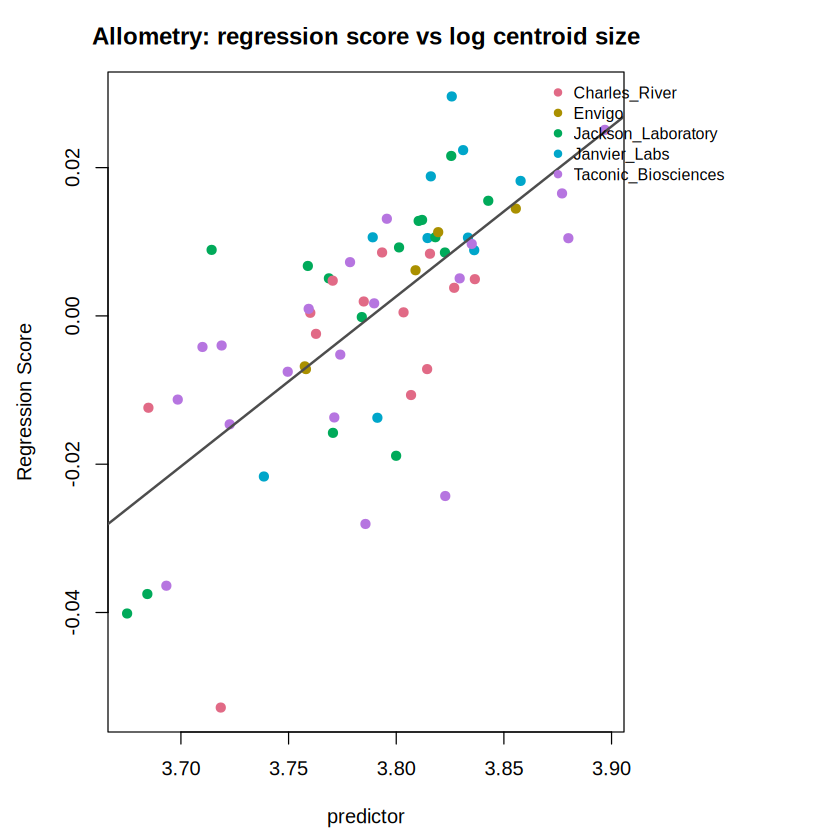

In [ ]:
cols <- hcl.colors(nlevels(locality), "Dark 3")
par(mar = c(4.5, 4.5, 3, 9))
pa <- plotAllometry(fit.null, size = gdf$Csize, logsz = TRUE,
                    method = "RegScore", col = cols[locality], pch = 19)
abline(lm(pa$RegScore ~ log(gdf$Csize)), lwd = 2, col = "grey30")
title("Allometry: regression score vs log centroid size")
par(xpd = TRUE)
legend("topright", inset = c(-0.3, 0), legend = levels(locality),
       col = cols, pch = 19, bty = "n", cex = 0.8)
par(xpd = FALSE)

## 12. Save your results

PC scores joined to the metadata, so you can plot them elsewhere — in ggplot2, in
SlicerMorph, or in a spreadsheet.

In Colab, written files appear under the folder icon in the left sidebar —
right-click a file there to download it. Files vanish when the runtime
disconnects, so save anything you want to keep.

In [ ]:
write.csv(data.frame(info, PC1 = pca$x[,1], PC2 = pca$x[,2]), "pc_scores.csv", row.names = FALSE)

## Where to go next

- **Swap in your own data.** Replace the download in step 2 with your own
  `.mrk.json` or `.fcsv` files and your own metadata CSV in step 4. Everything
  downstream works unchanged, as long as every specimen has the same landmarks
  in the same order.
- **Semi-landmarks.** Curve and surface points need to slide during GPA: pass
  `curves =` and `surfaces =` to `gpagen()`.
- **Interactive 3D.** Locally (not in Colab) drop the `rgl.useNULL` line and
  `plotRefToTarget()` gives you a rotatable 3D deformation.
- **More of geomorph.** `morphol.disparity()` for variation within groups,
  `pairwise()` for which group pairs differ, `procD.pgls()` to account for
  phylogeny.

Reference: [geomorph on CRAN](https://cran.r-project.org/package=geomorph) ·
[SlicerMorph tutorials](https://github.com/SlicerMorph/Tutorials)